<a href="https://colab.research.google.com/github/Nihat0311/Computer-Vision/blob/main/Underwater_semantic_segmentation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install -q kaggle
from google.colab import files
files.upload()

!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json
!kaggle datasets download -d islammomin/semantic-segmentation-of-underwater-imagery-suim
!unzip -q semantic-segmentation-of-underwater-imagery-suim.zip -d suim_dataset

Saving kaggle.json to kaggle.json
403 Client Error: Forbidden for url: https://api.kaggle.com/v1/datasets.DatasetApiService/GetDatasetMetadata
unzip:  cannot find or open semantic-segmentation-of-underwater-imagery-suim.zip, semantic-segmentation-of-underwater-imagery-suim.zip.zip or semantic-segmentation-of-underwater-imagery-suim.zip.ZIP.


In [ ]:
!rm -rf suim_dataset semantic-segmentation-of-underwater-imagery-suim.zip
!kaggle datasets download -d ashish2001/semantic-segmentation-of-underwater-imagery-suim
!unzip -q semantic-segmentation-of-underwater-imagery-suim.zip -d suim_dataset

Dataset URL: https://www.kaggle.com/datasets/ashish2001/semantic-segmentation-of-underwater-imagery-suim
License(s): copyright-authors
100% 176M/176M [00:10<00:00, 18.2MB/s]



In [ ]:
import os
import numpy as np
from PIL import Image
import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
import matplotlib.pyplot as plt

IMAGE_DIR = "suim_dataset/train_val/images"
MASK_DIR = "suim_dataset/train_val/masks"

class SUIMDataset(Dataset):
    def __init__(self, image_dir, mask_dir, img_size=(256, 256)):
        self.image_dir = image_dir
        self.mask_dir = mask_dir
        self.img_size = img_size
        self.images = os.listdir(image_dir)

        self.transform_img = transforms.Compose([
            transforms.Resize(self.img_size),
            transforms.ToTensor(),
            transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
        ])

        self.transform_mask = transforms.Compose([
            transforms.Resize(self.img_size, interpolation=Image.NEAREST)
        ])

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):
        img_name = self.images[idx]
        img_path = os.path.join(self.image_dir, img_name)

        mask_name = img_name.split('.')[0] + '.bmp'
        mask_path = os.path.join(self.mask_dir, mask_name)

        image = Image.open(img_path).convert("RGB")
        mask = Image.open(mask_path).convert("L")

        image = self.transform_img(image)
        mask = self.transform_mask(mask)

        mask = torch.from_numpy(np.array(mask, dtype=np.int64))

        return image, mask

dataset = SUIMDataset(IMAGE_DIR, MASK_DIR)
train_loader = DataLoader(dataset, batch_size=8, shuffle=True, num_workers=2)

print(f"Ümumi şəkil sayı: {len(dataset)}")


images, masks = next(iter(train_loader))
print(f"Şəkil batch ölçüsü: {images.shape}") # (Batch, Channel, Height, Width)
print(f"Maska batch ölçüsü: {masks.shape}")   # (Batch, Height, Width)

Ümumi şəkil sayı: 1525
Şəkil batch ölçüsü: torch.Size([8, 3, 256, 256])
Maska batch ölçüsü: torch.Size([8, 256, 256])


In [ ]:
import torch.nn as nn
import torch.nn.functional as F

def double_conv(in_channels, out_channels):
    """Ardıcıl iki konvolusiya qatı (Conv -> BN -> ReLU)"""
    return nn.Sequential(
        nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1),
        nn.BatchNorm2d(out_channels),
        nn.ReLU(inplace=True),
        nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1),
        nn.BatchNorm2d(out_channels),
        nn.ReLU(inplace=True)
    )

class UNet(nn.Module):
    def __init__(self, n_classes):
        super(UNet, self).__init__()

        # Encoder (Aşağıya doğru yol)
        self.dconv_down1 = double_conv(3, 64)
        self.dconv_down2 = double_conv(64, 128)
        self.dconv_down3 = double_conv(128, 256)
        self.dconv_down4 = double_conv(256, 512)

        self.maxpool = nn.MaxPool2d(2)
        self.upsample = nn.Upsample(scale_factor=2, mode='bilinear', align_corners=True)

        # Decoder (Yuxarıya doğru yol)
        self.dconv_up3 = double_conv(256 + 512, 256)
        self.dconv_up2 = double_conv(128 + 256, 128)
        self.dconv_up1 = double_conv(64 + 128, 64)

        # Çıxış qatı: Hər piksel üçün sinif proqnozu
        self.conv_last = nn.Conv2d(64, n_classes, kernel_size=1)

    def forward(self, x):
        # Encoder
        conv1 = self.dconv_down1(x)
        x = self.maxpool(conv1)

        conv2 = self.dconv_down2(x)
        x = self.maxpool(conv2)

        conv3 = self.dconv_down3(x)
        x = self.maxpool(conv3)

        x = self.dconv_down4(x)

        # Decoder + Skip Connections
        x = self.upsample(x)
        x = torch.cat([x, conv3], dim=1)

        x = self.dconv_up3(x)
        x = self.upsample(x)
        x = torch.cat([x, conv2], dim=1)

        x = self.dconv_up2(x)
        x = self.upsample(x)
        x = torch.cat([x, conv1], dim=1)

        x = self.dconv_up1(x)

        out = self.conv_last(x)
        return out

NUM_CLASSES = 8
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model = UNet(NUM_CLASSES).to(device)

print(f"Model {device} cihazında quruldu.")

Model cuda cihazında quruldu.


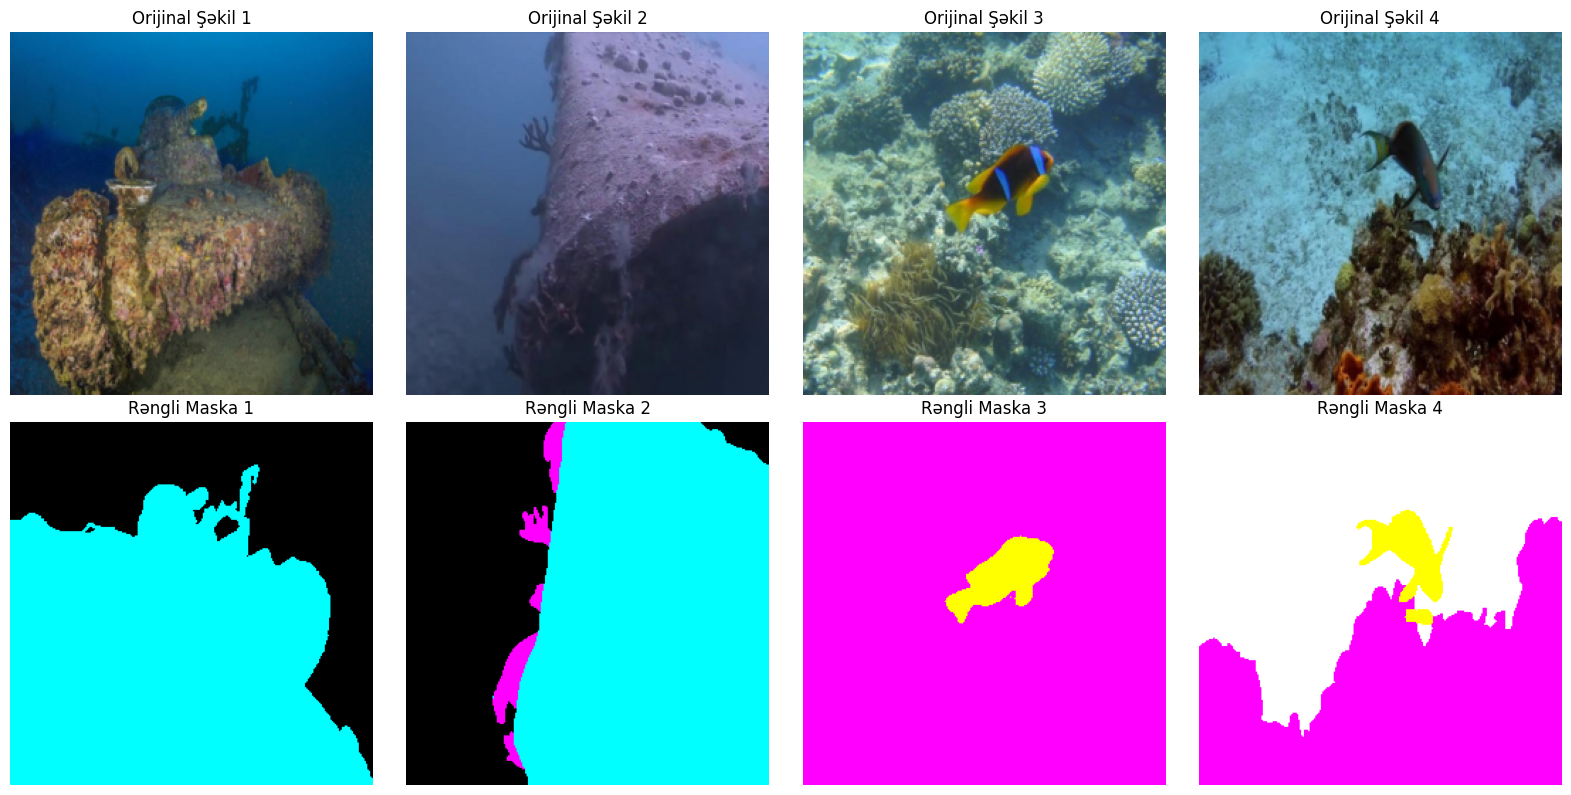

In [ ]:
import os
import numpy as np
from PIL import Image
import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
import matplotlib.pyplot as plt

SUIM_COLORS = np.array([
    [0, 0, 0],       # 0: BW (Arxaplan/Su) - Qara
    [0, 0, 255],     # 1: HD (Dalğıclar) - Mavi
    [0, 255, 0],     # 2: PF (Bitkilər) - Yaşıl
    [0, 255, 255],   # 3: WR (Qalıqlar/Gəmilər) - Açıq Mavi (Cyan)
    [255, 0, 0],     # 4: RO (Robotlar) - Qırmızı
    [255, 0, 255],   # 5: RI (Riflər) - Çəhrayı/Magent
    [255, 255, 0],   # 6: FV (Balıqlar) - Sarı
    [255, 255, 255]  # 7: SR (Dəniz dibi/Daşlar) - Ağ
])

def rgb_to_index(mask_np):
    """Rəngli maskanı modelin başa düşəcəyi 0-7 arası sinif indeksinə çevirir."""
    flat_mask = mask_np.reshape(-1, 3)
    # Hər bir pikselin bizim 8 rəngimizdən hansına ən yaxın olduğunu tapırıq
    distances = np.linalg.norm(flat_mask[:, None, :] - SUIM_COLORS[None, :, :], axis=2)
    indices = np.argmin(distances, axis=1)
    return indices.reshape(mask_np.shape[:2])

def index_to_rgb(mask_idx):
    """0-7 arası indeksi vizualizasiya üçün yenidən rəngli (RGB) maskaya çevirir."""
    return SUIM_COLORS[mask_idx].astype(np.uint8)

# Dataset sinfini RGB dəstəyi ilə yenidən qururuq
class SUIMDatasetRGB(Dataset):
    def __init__(self, image_dir, mask_dir, img_size=(256, 256)):
        self.image_dir = image_dir
        self.mask_dir = mask_dir
        self.img_size = img_size
        self.images = os.listdir(image_dir)

        self.transform_img = transforms.Compose([
            transforms.Resize(self.img_size),
            transforms.ToTensor(),
            transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
        ])

        self.transform_mask = transforms.Compose([
            transforms.Resize(self.img_size, interpolation=Image.NEAREST)
        ])

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):
        img_name = self.images[idx]
        img_path = os.path.join(self.image_dir, img_name)
        mask_name = img_name.split('.')[0] + '.bmp'
        mask_path = os.path.join(self.mask_dir, mask_name)

        # Həm şəkli, həm də MASKANI RGB formatında oxuyuruq
        image = Image.open(img_path).convert("RGB")
        mask = Image.open(mask_path).convert("RGB")

        image = self.transform_img(image)
        mask = self.transform_mask(mask)

        # Rəngli maskanı 0-7 indekslərinə çeviririk (Modelin ehtiyacı olan format)
        mask_idx = rgb_to_index(np.array(mask))
        mask_tensor = torch.from_numpy(mask_idx).long()

        return image, mask_tensor

# Yenilənmiş Dataloader
IMAGE_DIR = "suim_dataset/train_val/images"
MASK_DIR = "suim_dataset/train_val/masks"
dataset_rgb = SUIMDatasetRGB(IMAGE_DIR, MASK_DIR)
train_loader_rgb = DataLoader(dataset_rgb, batch_size=4, shuffle=True, num_workers=2)

# ---- VİZUALİZASİYA BÖLMƏSİ ----
images, masks = next(iter(train_loader_rgb))

fig, axs = plt.subplots(2, 4, figsize=(16, 8))
for i in range(4):
    # Şəkli Tensor-dan normal şəkil formatına qaytarırıq ki, ekranda göstərə bilək
    img = images[i].permute(1, 2, 0).numpy()
    img = img * np.array([0.229, 0.224, 0.225]) + np.array([0.485, 0.456, 0.406])
    img = np.clip(img, 0, 1)

    # Modelin istifadə etdiyi indeksli maskanı EKRANDA GÖRMƏK ÜÇÜN RƏNGLİ edirik
    colored_mask = index_to_rgb(masks[i].numpy())

    axs[0, i].imshow(img)
    axs[0, i].set_title(f"Orijinal Şəkil {i+1}")
    axs[0, i].axis("off")

    axs[1, i].imshow(colored_mask)
    axs[1, i].set_title(f"Rəngli Maska {i+1}")
    axs[1, i].axis("off")

plt.tight_layout()
plt.show()

In [ ]:
import torch.nn as nn
import torch.nn.functional as F

class DiceLoss(nn.Module):
    def __init__(self, smooth=1e-6):
        super(DiceLoss, self).__init__()
        self.smooth = smooth

    def forward(self, logits, targets):
        probs = F.softmax(logits, dim=1)
        num_classes = logits.shape[1]
        targets_one_hot = F.one_hot(targets, num_classes).permute(0, 3, 1, 2).float()
        intersection = (probs * targets_one_hot).sum(dim=(0, 2, 3))
        total = (probs + targets_one_hot).sum(dim=(0, 2, 3))
        dice = (2. * intersection + self.smooth) / (total + self.smooth)
        return 1 - dice.mean()

class FocalLoss(nn.Module):
    def __init__(self, alpha=1, gamma=2):
        super(FocalLoss, self).__init__()
        self.alpha = alpha
        self.gamma = gamma

    def forward(self, logits, targets):
        ce_loss = F.cross_entropy(logits, targets, reduction='none')
        pt = torch.exp(-ce_loss)
        focal_loss = self.alpha * (1 - pt)**self.gamma * ce_loss
        return focal_loss.mean()
class CombinedLoss(nn.Module):
    def __init__(self):
        super(CombinedLoss, self).__init__()
        self.dice = DiceLoss()
        self.focal = FocalLoss()

    def forward(self, logits, targets):
        return self.dice(logits, targets) + self.focal(logits, targets)

criterion = CombinedLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)

In [ ]:
def calculate_metrics(preds, targets, num_classes=8):
    preds = torch.argmax(preds, dim=1)
    correct = (preds == targets).sum().item()
    total_pixels = targets.numel()
    acc = correct / total_pixels

    dice_list = []
    for cls in range(num_classes):
        p = (preds == cls).float()
        t = (targets == cls).float()
        intersection = (p * t).sum().item()
        union = p.sum().item() + t.sum().item()
        if union == 0:
            dice_list.append(1.0)
        else:
            dice_list.append((2. * intersection) / union)
    return acc, np.mean(dice_list)

In [ ]:
from torch.utils.data import random_split

# Dataseti bölürük
train_size = int(0.8 * len(dataset_rgb))
val_size = len(dataset_rgb) - train_size
train_ds, val_ds = random_split(dataset_rgb, [train_size, val_size])

train_loader = DataLoader(train_ds, batch_size=8, shuffle=True)
val_loader = DataLoader(val_ds, batch_size=8, shuffle=False)

def train_and_validate(model, train_loader, val_loader, criterion, optimizer, epochs=15):
    history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': [], 'train_dice': [], 'val_dice': []}

    for epoch in range(epochs):
        model.train()
        t_loss, t_acc, t_dice = 0, 0, 0
        for imgs, masks in train_loader:
            imgs, masks = imgs.to(device), masks.to(device)
            optimizer.zero_grad()
            outputs = model(imgs)
            loss = criterion(outputs, masks)
            loss.backward()
            optimizer.step()

            acc, dice = calculate_metrics(outputs, masks)
            t_loss += loss.item(); t_acc += acc; t_dice += dice

        model.eval()
        v_loss, v_acc, v_dice = 0, 0, 0
        with torch.no_grad():
            for imgs, masks in val_loader:
                imgs, masks = imgs.to(device), masks.to(device)
                outputs = model(imgs)
                loss = criterion(outputs, masks)
                acc, dice = calculate_metrics(outputs, masks)
                v_loss += loss.item(); v_acc += acc; v_dice += dice

        # Nəticələri ekrana çıxarırıq
        res = {
            't_l': t_loss/len(train_loader), 'v_l': v_loss/len(val_loader),
            't_a': t_acc/len(train_loader), 'v_a': v_acc/len(val_loader),
            't_d': t_dice/len(train_loader), 'v_d': v_dice/len(val_loader)
        }
        print(f"Epoch [{epoch+1}/{epochs}] | Train Acc: {res['t_a']:.3f}, Val Acc: {res['v_a']:.3f} | Val Dice: {res['v_d']:.3f}")

        history['train_loss'].append(res['t_l']); history['val_loss'].append(res['v_l'])
        history['train_acc'].append(res['t_a']); history['val_acc'].append(res['v_a'])
        history['train_dice'].append(res['t_d']); history['val_dice'].append(res['v_d'])

    return history

In [ ]:
history = train_and_validate(model, train_loader, val_loader, criterion, optimizer, epochs=15)

Epoch [1/15] | Train Acc: 0.661, Val Acc: 0.666 | Val Dice: 0.411
Epoch [2/15] | Train Acc: 0.672, Val Acc: 0.682 | Val Dice: 0.445
Epoch [3/15] | Train Acc: 0.683, Val Acc: 0.668 | Val Dice: 0.451
Epoch [4/15] | Train Acc: 0.688, Val Acc: 0.692 | Val Dice: 0.435
Epoch [5/15] | Train Acc: 0.695, Val Acc: 0.695 | Val Dice: 0.431
Epoch [6/15] | Train Acc: 0.700, Val Acc: 0.657 | Val Dice: 0.461
Epoch [7/15] | Train Acc: 0.707, Val Acc: 0.697 | Val Dice: 0.443
Epoch [8/15] | Train Acc: 0.708, Val Acc: 0.705 | Val Dice: 0.456
Epoch [9/15] | Train Acc: 0.710, Val Acc: 0.700 | Val Dice: 0.465
Epoch [10/15] | Train Acc: 0.720, Val Acc: 0.704 | Val Dice: 0.426
Epoch [11/15] | Train Acc: 0.718, Val Acc: 0.721 | Val Dice: 0.474
Epoch [12/15] | Train Acc: 0.726, Val Acc: 0.716 | Val Dice: 0.498
Epoch [13/15] | Train Acc: 0.731, Val Acc: 0.717 | Val Dice: 0.495
Epoch [14/15] | Train Acc: 0.733, Val Acc: 0.722 | Val Dice: 0.487
Epoch [15/15] | Train Acc: 0.738, Val Acc: 0.723 | Val Dice: 0.497
